<a href="https://colab.research.google.com/github/Chxte/128-445-Data-Warehouse-and-Data-Mining/blob/main/weather.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [98]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler

In [99]:
df = pd.read_csv('/content/sample_data/weatherAUS.csv')
print('---(แถว x คอลัมน์)---')
print(df.shape)
print('\n---(ข้อมูล 5 แถวแรก)---')
print(df.head())

---(แถว x คอลัมน์)---
(145460, 23)

---(ข้อมูล 5 แถวแรก)---
         Date Location  MinTemp  MaxTemp  Rainfall  Evaporation  Sunshine  \
0  2008-12-01   Albury     13.4     22.9       0.6          NaN       NaN   
1  2008-12-02   Albury      7.4     25.1       0.0          NaN       NaN   
2  2008-12-03   Albury     12.9     25.7       0.0          NaN       NaN   
3  2008-12-04   Albury      9.2     28.0       0.0          NaN       NaN   
4  2008-12-05   Albury     17.5     32.3       1.0          NaN       NaN   

  WindGustDir  WindGustSpeed WindDir9am  ... Humidity9am  Humidity3pm  \
0           W           44.0          W  ...        71.0         22.0   
1         WNW           44.0        NNW  ...        44.0         25.0   
2         WSW           46.0          W  ...        38.0         30.0   
3          NE           24.0         SE  ...        45.0         16.0   
4           W           41.0        ENE  ...        82.0         33.0   

   Pressure9am  Pressure3pm  Cloud9am 

Date – วันที่ตรวจวัดสภาพอากาศ

Location – ชื่อเมืองหรือสถานีตรวจวัดในออสเตรเลีย

MinTemp – อุณหภูมิต่ำสุดในรอบวัน (°C)

MaxTemp – อุณหภูมิสูงสุดในรอบวัน (°C)

Rainfall – ปริมาณน้ำฝนสะสมในรอบ 24 ชั่วโมง (mm)

Evaporation – ปริมาณการระเหยของน้ำ (mm)

Sunshine – จำนวนชั่วโมงที่มีแสงแดดจ้าในรอบวัน (ชั่วโมง)

WindGustDir – ทิศทางของลมกระโชกแรงที่สุดในรอบวัน

WindGustSpeed – ความเร็วของลมกระโชกแรงที่สุดในรอบวัน (km/h)

WindDir9am – ทิศทางลมเฉลี่ยตอน 9:00 น.

WindDir3pm – ทิศทางลมเฉลี่ยตอน 15:00 น.

WindSpeed9am – ความเร็วลมเฉลี่ยตอน 9:00 น. (km/h)

WindSpeed3pm – ความเร็วลมเฉลี่ยตอน 15:00 น. (km/h)

Humidity9am – ความชื้นสัมพัทธ์ตอน 9:00 น. (%)

Humidity3pm – ความชื้นสัมพัทธ์ตอน 15:00 น. (%)

Pressure9am – ความกดอากาศตอน 9:00 น. (hPa)

Pressure3pm – ความกดอากาศตอน 15:00 น. (hPa)

Cloud9am – ปริมาณเมฆปกคลุมท้องฟ้าตอน 9:00 น. (สเกล 0–8)

Cloud3pm – ปริมาณเมฆปกคลุมท้องฟ้าตอน 15:00 น. (สเกล 0–8)

Temp9am – อุณหภูมิตอน 9:00 น. (°C)

Temp3pm – อุณหภูมิตอน 15:00 น. (°C)

RainToday – วันนี้ฝนตกหรือไม่ (Yes = ฝนตกเกิน 1 mm / No = ไม่ตก)

RainTomorrow – พรุ่งนี้ฝนจะตกหรือไม่ (Yes / No)

=== จำนวน Missing Values ในแต่ละคอลัมน์ ===


,Missing Count,Missing %
Sunshine,69835,48.01
Evaporation,62790,43.17
Cloud3pm,59358,40.81
Cloud9am,55888,38.42
Pressure9am,15065,10.36
Pressure3pm,15028,10.33
WindDir9am,10566,7.26
WindGustDir,10326,7.10
WindGustSpeed,10263,7.06
Humidity3pm,4507,3.10


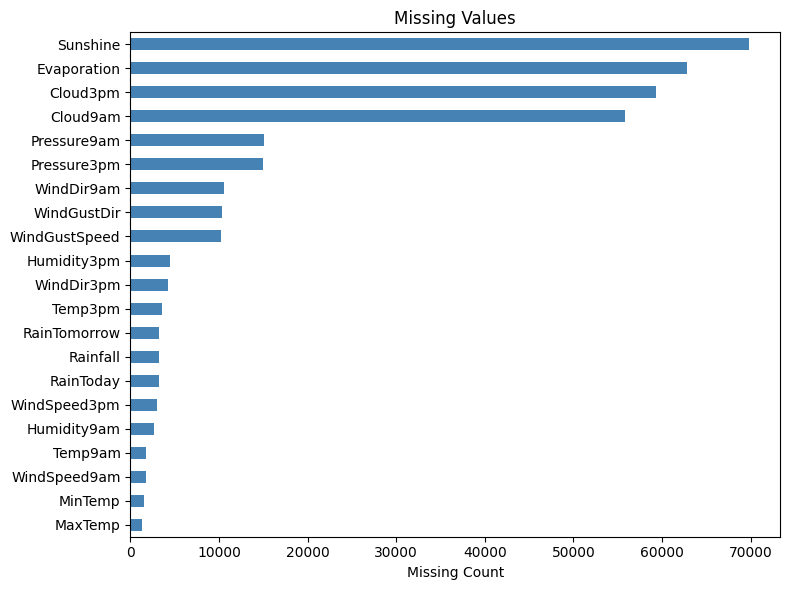

In [100]:
print('=== จำนวน Missing Values ในแต่ละคอลัมน์ ===')
missing = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
display(missing_df[missing_df['Missing Count'] > 0].sort_values('Missing %', ascending=False))

plt.figure(figsize=(8,6))
missing[missing > 0].sort_values().plot(kind='barh', color='steelblue')
plt.title('Missing Values')
plt.xlabel('Missing Count')
plt.tight_layout()
plt.show()

In [101]:
df = df.dropna(subset=['RainTomorrow','RainToday','Rainfall'])

df['RainTomorrow'] = (df['RainTomorrow'] == 'Yes').astype(int)
df['RainToday'] = (df['RainToday'] == 'Yes').astype(int)
df['Date'] = pd.to_datetime(df['Date'])
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df = df.drop(columns=['Date'])
df[['Month','Year']].head()

,Month,Year
0,12,2008
1,12,2008
2,12,2008
3,12,2008
4,12,2008


In [102]:
for c in['Evaporation','Sunshine','Cloud9am','Cloud3pm']:
  df[c+'_missing']=df[c].isna().astype(int)
wind = ['WindGustDir','WindDir9am','WindDir3pm']
df[wind] = df[wind].fillna('Unknow')
df=df.fillna(df.median(numeric_only=True))

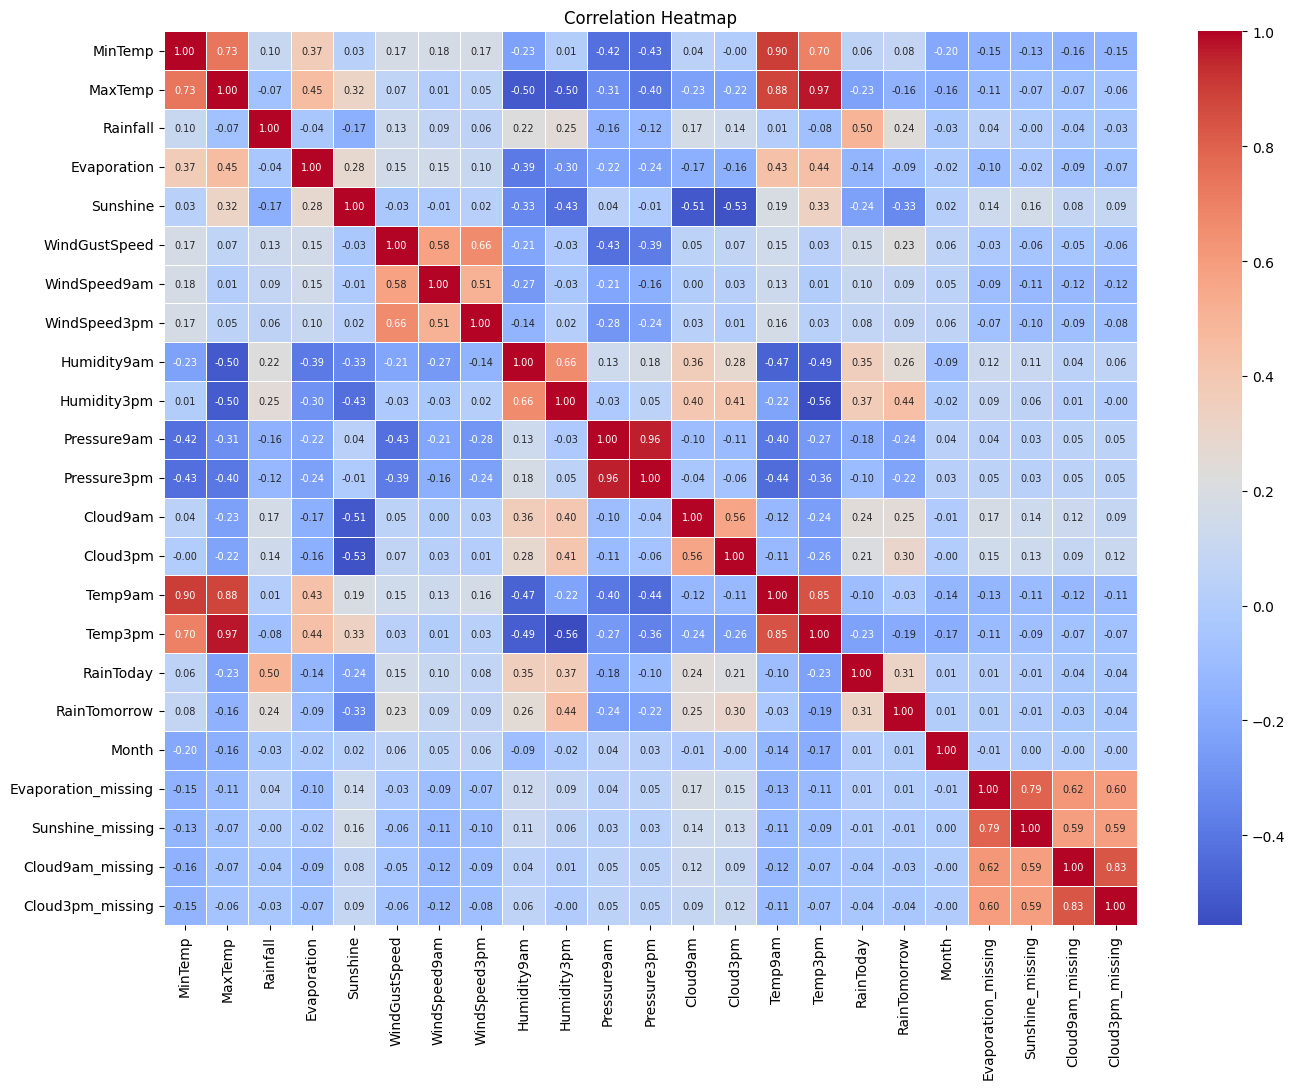

In [103]:
corr = df.drop(columns=['Year']).select_dtypes(include=np.number).corr()

plt.figure(figsize=(14,11))
sns.heatmap(corr,annot=True,cmap='coolwarm', fmt=".2f",linewidths=.5, annot_kws={'size':7})
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [ ]:
df = pd.get_dummies(df, columns=['Location']+ wind)
print(df.shape)

In [105]:
train = df[df['Year'] < 2016]
test = df[df['Year'] >= 2016]

X_train = train.drop(columns=['RainTomorrow','Year'])
y_train = train['RainTomorrow']
X_test = test.drop(columns=['RainTomorrow','Year'])
y_test = test['RainTomorrow']

In [106]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(),
}

results = []
trained_models = {}

for name, model in models.items():
    if name == "Logistic Regression":
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True, zero_division=0)

    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": report["weighted avg"]["precision"],
        "Recall": report["weighted avg"]["recall"],
        "F1-score": report["weighted avg"]["f1-score"]
    })

    trained_models[name] = model

results_df = pd.DataFrame(results).sort_values(by="F1-score", ascending=False)
print("\nModel comparison:")
print(results_df)


Model comparison:
                 Model  Accuracy  Precision    Recall  F1-score
2        Random Forest  0.847530   0.839034  0.847530  0.833893
0  Logistic Regression  0.843096   0.833090  0.843096  0.831039
1        Decision Tree  0.779113   0.781210  0.779113  0.780131


In [107]:
def predict_rain(data, model_name="Random Forest"):
    df = pd.DataFrame([data])
    df["RainToday"] = (df["Rainfall"] >= 1).astype(int)
    df = pd.get_dummies(df, columns=['Location'] + wind).reindex(columns=X_train.columns, fill_value=0)
    return trained_models[model_name].predict_proba(df)[0][1]

In [113]:
new_data = pd.DataFrame([{
    "Location":"Sydney",
    "MinTemp":23.2,
    "MaxTemp":33.2,
    "Rainfall":10.2,
    "Evaporation":4.2,
    "Sunshine":6.2,
    "WindGustDir":"W",
    "WindGustSpeed":52.0,
    "WindDir9am":"W",
    "WindDir3pm":"W",
    "WindSpeed9am":13.0,
    "WindSpeed3pm":20.0,
    "Humidity9am":55.0,
    "Humidity3pm":55.0,
    "Pressure9am":1004.8,
    "Pressure3pm":1001.5,
    "Cloud9am":8.0,
    "Cloud3pm":5.0,
    "Temp9am":25.7,
    "Temp3pm":33.0,
    "RainToday":1,
    "Month":7
}])

prob = predict_rain(new_data.iloc[0].to_dict(), "Random Forest")
print(f"โอกาสฝนตก = {prob:.1%} → {' ตก' if prob >= 0.5 else ' ไม่ตก'}")

โอกาสฝนตก = 50.0% →  ตก
